# Calibration và đánh giá POC — LightGBM với chu kỳ mua

So sánh hai phương án đã định trước: **18 feature** và **18 + chu kỳ mua**. Quy tắc chọn calibration được cố định và đánh giá trên các giai đoạn bên trong train trước khi đọc validation hoặc test. Sau đó hai pipeline đã cố định được đánh giá trên validation và test theo thời gian.

Test của project đã từng được xem trong quá trình phát triển. Vì vậy kết quả ở đây là tham khảo cho POC, không phải xác nhận độc lập hay bằng chứng hiệu quả marketing.

Ứng viên chính được xác định trước là 18 + chu kỳ; 18 feature là đối chứng. Kết quả test không được sử dụng để chọn lại phương án.

## 1. Chia thời gian để fit và chọn calibration

Để tránh hiệu chỉnh và đánh giá trên cùng dữ liệu, chia train thành ba giai đoạn:

| Mục đích | Cutoff |
|---|---|
| Fit LightGBM | 180–439 |
| Fit sigmoid calibration | 453–481 |
| Chọn dùng sigmoid hay xác suất thô | 495–537 |

Cutoff 446 và 488 được bỏ làm embargo. Quy tắc định trước: dùng sigmoid nếu log loss trên giai đoạn chọn giảm **ít nhất 0,001** và Brier không tăng so với xác suất thô. Ngưỡng 0,001 là lựa chọn thực hành, không phải kiểm định ý nghĩa thống kê. Không điều chỉnh quy tắc sau khi xem validation/test.

Hai pipeline cuối giữ LightGBM được fit đến cutoff 439 và calibrator đã fit ở 453–481 nếu được chọn; **không refit trên toàn bộ train** vì khi đó bộ hiệu chỉnh đã học từ dự báo của mô hình khác. Đổi lại, mô hình chưa sử dụng các cutoff sau 439 để học LightGBM.

In [1]:
from pathlib import Path
import sys,json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from scipy.special import logit
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss,log_loss,roc_auc_score
from IPython.display import display
ROOT=Path.cwd()
if ROOT.name == 'research' and ROOT.parent.name == 'notebooks': ROOT = ROOT.parent
if ROOT.name=='notebooks':ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'src'))
if (ROOT/'.deps').is_dir():sys.path.insert(0,str(ROOT/'.deps'))
from propensity_v2.prepared_data import load_prepared_split
from lightgbm import LGBMClassifier
import lightgbm
DATA=ROOT/'artifacts'/'data_preparation';OUT=ROOT/'artifacts'/'calibration_final_poc'
train,base_features=load_prepared_split(DATA,'train')
fit_days=train.snapshot_day.between(180,439)
cal_days=train.snapshot_day.between(453,481)
select_days=train.snapshot_day.between(495,537)
assert train.loc[fit_days,'snapshot_day'].max()+7 < train.loc[cal_days,'snapshot_day'].min()
assert train.loc[cal_days,'snapshot_day'].max()+7 < train.loc[select_days,'snapshot_day'].min()
print('Fit:',fit_days.sum(),'| Fit calibration:',cal_days.sum(),'| Chọn calibration:',select_days.sum())

Fit: 94862 | Fit calibration: 12490 | Chọn calibration: 17486


## 2. Tạo chu kỳ theo đúng cutoff

Khoảng cách tính giữa các ngày có basket trong `(s-180,s]`. Median, độ lệch chuẩn và tỷ lệ recency/median được giữ thiếu khi không đủ dữ liệu; hai cờ mô tả số khoảng cách sẵn có. Feature xây dựng riêng tại từng cutoff, không dùng giao dịch sau cutoff.

In [2]:
cadence_features=['cadence_median_gap_180d','cadence_gap_std_180d','cadence_recency_ratio','cadence_has_gap','cadence_has_two_gaps']
def add_cadence(panel,active):
    parts=[]
    for s in sorted(panel.snapshot_day.unique()):
        current=panel.loc[panel.snapshot_day.eq(s),['household_key','snapshot_day','recency_days']].set_index('household_key').copy()
        d=active.loc[active.DAY.between(s-179,s)].copy()
        d['gap']=d.groupby('household_key').DAY.diff()
        g=d.groupby('household_key').gap.agg(['count','median','std'])
        current['cadence_median_gap_180d']=g['median'];current['cadence_gap_std_180d']=g['std']
        current['cadence_has_gap']=g['count'].ge(1).reindex(current.index,fill_value=False).astype(int)
        current['cadence_has_two_gaps']=g['count'].ge(2).reindex(current.index,fill_value=False).astype(int)
        current['cadence_recency_ratio']=current.recency_days/current.cadence_median_gap_180d
        parts.append(current.reset_index()[['household_key','snapshot_day']+cadence_features])
    result=panel.merge(pd.concat(parts,ignore_index=True),on=['household_key','snapshot_day'],validate='one_to_one')
    assert len(result)==len(panel) and not result[cadence_features].isin([np.inf,-np.inf]).any().any()
    return result
raw=pd.read_csv(ROOT/'sample_data'/'dunnhumby'/'transaction_data.csv',usecols=['household_key','DAY'])
active_train=(raw.loc[raw.DAY<=537].drop_duplicates().sort_values(['household_key','DAY']))
train=add_cadence(train,active_train)
print('Đã tạo chu kỳ cho train:',len(train))

Đã tạo chu kỳ cho train: 129834


## 3. Fit model, fit và chọn calibration

Sigmoid được fit trên logit của xác suất LightGBM. Hai bộ feature được xem như hai phương án đối chứng; quy tắc chọn calibration áp dụng độc lập cho từng phương án. Sau cell này, cấu hình, feature, cutoff và calibration của cả hai được cố định trước khi đọc các nhãn validation/test.

In [3]:
EPS=1e-6
def score(y,p):
    return {'brier':brier_score_loss(y,p),'log_loss':log_loss(y,p,labels=[0,1]),
            'roc_auc':roc_auc_score(y,p) if pd.Series(y).nunique()==2 else np.nan}
def as_logit(p):return logit(np.clip(p,EPS,1-EPS)).reshape(-1,1)
bundles={}; selection=[]
for name,cols in [('18 feature',base_features),('18 + chu kỳ',base_features+cadence_features)]:
    model=LGBMClassifier(n_estimators=200,learning_rate=.05,num_leaves=15,min_child_samples=100,random_state=42,verbosity=-1,n_jobs=2)
    model.fit(train.loc[fit_days,cols],train.loc[fit_days,'target_any_basket'])
    raw_cal=model.predict_proba(train.loc[cal_days,cols])[:,1]
    calibrator=LogisticRegression(C=1e6,solver='lbfgs',max_iter=1000,random_state=42)
    calibrator.fit(as_logit(raw_cal),train.loc[cal_days,'target_any_basket'])
    raw_select=model.predict_proba(train.loc[select_days,cols])[:,1]
    calibrated_select=calibrator.predict_proba(as_logit(raw_select))[:,1]
    a=score(train.loc[select_days,'target_any_basket'],raw_select)
    b=score(train.loc[select_days,'target_any_basket'],calibrated_select)
    use_calibration=(b['log_loss'] <= a['log_loss']-.001 and b['brier'] <= a['brier'])
    bundles[name]={'model':model,'calibrator':calibrator if use_calibration else None,'features':cols}
    selection.append({'feature_set':name,'raw_log_loss':a['log_loss'],'sigmoid_log_loss':b['log_loss'],
                      'raw_brier':a['brier'],'sigmoid_brier':b['brier'],'chosen':'sigmoid' if use_calibration else 'raw'})
selection=pd.DataFrame(selection);display(selection)
assert len(bundles)==2

,feature_set,raw_log_loss,sigmoid_log_loss,raw_brier,sigmoid_brier,chosen
0,18 feature,0.496930,0.496889,0.164990,0.164956,raw
1,18 + chu kỳ,0.496688,0.496609,0.164928,0.164901,raw


## 4. Đánh giá trên validation và test

Chỉ sau khi đã cố định pipeline ở trên, nạp validation và test. Không thay đổi feature, model hay calibration theo kết quả. Brier và log loss đo xác suất; ROC-AUC đo thứ tự; lift top 10% được tính riêng mỗi cutoff, xử lý đồng điểm bằng kỳ vọng chọn ngẫu nhiên và lấy trung bình qua cutoff. Các household lặp lại nên các hàng không độc lập.

In [4]:
validation,vfeatures=load_prepared_split(DATA,'validation')
test,tfeatures=load_prepared_split(DATA,'test')
assert base_features==vfeatures==tfeatures
assert train.loc[select_days,'snapshot_day'].max()+7 < validation.snapshot_day.min()
assert validation.snapshot_day.max()+7 < test.snapshot_day.min()
active_all=(raw.loc[raw.DAY<=max(validation.snapshot_day.max(),test.snapshot_day.max())]
            .drop_duplicates().sort_values(['household_key','DAY']))
validation=add_cadence(validation,active_all);test=add_cadence(test,active_all)
def top_lift(g,p):
    y=g.target_any_basket.to_numpy();k=int(np.ceil(.1*len(y)));t=np.partition(p,len(p)-k)[len(p)-k]
    high=p>t;tie=p==t;return ((y[high].sum()+(k-high.sum())*y[tie].mean())/k)/y.mean() if y.mean() else np.nan
def predict(bundle,frame):
    p=bundle['model'].predict_proba(frame[bundle['features']])[:,1]
    return bundle['calibrator'].predict_proba(as_logit(p))[:,1] if bundle['calibrator'] is not None else p
metrics=[];weekly=[];predictions=[]
for split,frame in [('validation',validation),('test',test)]:
    frame=frame.reset_index(drop=True)
    for name,bundle in bundles.items():
        p=predict(bundle,frame)
        assert np.isfinite(p).all() and ((p>=0)&(p<=1)).all()
        ls=[]
        for day,ix in frame.groupby('snapshot_day').indices.items():
            g=frame.iloc[ix];lift=top_lift(g,p[ix]);ls.append(lift)
            weekly.append({'split':split,'feature_set':name,'snapshot_day':int(day),'rows':len(g),'lift':lift})
        metrics.append({'split':split,'feature_set':name,'rows':len(frame),**score(frame.target_any_basket,p),'weekly_lift_mean':np.nanmean(ls)})
        q=frame[['household_key','snapshot_day','target_any_basket']].copy();q['split']=split;q['feature_set']=name;q['probability']=p;predictions.append(q)
metrics=pd.DataFrame(metrics);weekly=pd.DataFrame(weekly);predictions=pd.concat(predictions,ignore_index=True)
display(metrics)

,split,feature_set,rows,brier,log_loss,roc_auc,weekly_lift_mean
0,validation,18 feature,27480,0.165599,0.498827,0.834966,1.785994
1,validation,18 + chu kỳ,27480,0.165523,0.498580,0.835198,1.791388
2,test,18 feature,24994,0.168325,0.505472,0.829951,1.822417
3,test,18 + chu kỳ,24994,0.168401,0.505456,0.829773,1.818039


## 5. Reliability và độ ổn định

Đường reliability dùng các bin xác suất cố định 0,1; số household-snapshot của từng bin được hiển thị trong bảng. Mẫu hộ lặp lại và dữ liệu test đã từng được xem khiến biểu đồ có giới hạn; không dùng kết quả để tinh chỉnh tiếp rồi trình bày lại như test mới.

,bin,n,mean_probability,observed,split,feature_set
0,"(-0.001, 0.1]",2275,0.066301,0.077802,test,18 + chu kỳ
1,"(0.1, 0.2]",2632,0.145494,0.190350,test,18 + chu kỳ
2,"(0.2, 0.3]",2180,0.249948,0.298624,test,18 + chu kỳ
3,"(0.3, 0.4]",2352,0.351160,0.358418,test,18 + chu kỳ
4,"(0.4, 0.5]",2338,0.447356,0.425577,test,18 + chu kỳ
5,"(0.5, 0.6]",2136,0.551710,0.539326,test,18 + chu kỳ
6,"(0.6, 0.7]",2290,0.651360,0.643231,test,18 + chu kỳ
7,"(0.7, 0.8]",2609,0.750490,0.729782,test,18 + chu kỳ
8,"(0.8, 0.9]",2673,0.849113,0.852226,test,18 + chu kỳ
9,"(0.9, 1.0]",3509,0.954016,0.948133,test,18 + chu kỳ


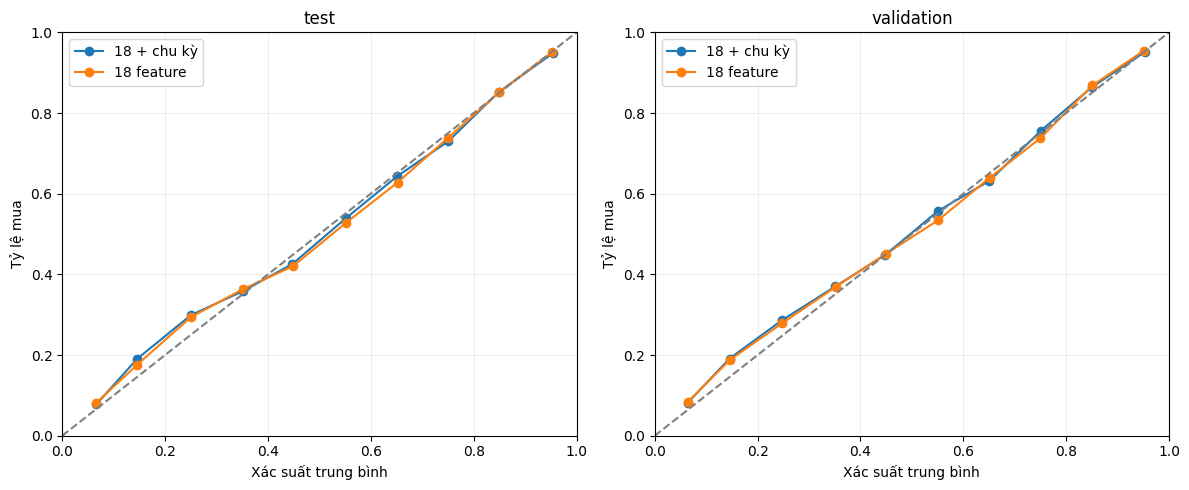

feature_set              18 + chu kỳ  18 feature
split      snapshot_day                         
test       635              1.680000    1.701000
           642              1.864206    1.864206
           649              1.760117    1.789453
           656              1.812009    1.804521
           663              1.863273    1.848000
           670              1.839985    1.832475
           677              1.777457    1.777457
           684              1.856604    1.849057
           691              1.835491    1.843107
           698              1.891253    1.914894
validation 551              1.840036    1.847577
           558              1.778991    1.778991
           565              1.763294    1.755947
           572              1.780312    1.758058
           579              1.870119    1.877847
           586              1.729660    1.743954
           593              1.773375    1.765924
           600              1.791923    1.762427
           607              1.734570    1.741858
           614              1.851669    1.844142
           621              1.791319    1.769204

In [5]:
bins=[]
for (split,name),g in predictions.groupby(['split','feature_set']):
    grouped=g.assign(bin=pd.cut(g.probability,np.linspace(0,1,11),include_lowest=True))
    t=grouped.groupby('bin',observed=True).agg(n=('probability','size'),mean_probability=('probability','mean'),observed=('target_any_basket','mean')).reset_index()
    t['split']=split;t['feature_set']=name;bins.append(t)
bins=pd.concat(bins,ignore_index=True);display(bins)
fig,axes=plt.subplots(1,2,figsize=(12,5))
for ax,(split,df) in zip(axes,bins.groupby('split',sort=False)):
    for name,g in df.groupby('feature_set'):ax.plot(g.mean_probability,g.observed,marker='o',label=name)
    ax.plot([0,1],[0,1],linestyle='--',color='gray');ax.set(xlim=(0,1),ylim=(0,1),title=split,xlabel='Xác suất trung bình',ylabel='Tỷ lệ mua');ax.grid(alpha=.2);ax.legend()
plt.tight_layout();plt.show()
display(weekly.pivot(index=['split','snapshot_day'],columns='feature_set',values='lift'))

**Nhận xét:** Tiêu chí chọn calibration không được đáp ứng cho cả hai phương án, nên cả hai giữ xác suất thô. Ứng viên 18 + chu kỳ có Brier 0,16840, log loss 0,50546, ROC-AUC 0,82977 và lift tuần 1,81804 trên test đã từng được xem. Đối chứng 18 feature có Brier 0,16833, log loss 0,50547, ROC-AUC 0,82995 và lift 1,82242; khác biệt nhỏ và không được dùng để chọn lại model. Hai LightGBM ở đây chỉ fit trên cutoff đến 439 vì tách riêng thời gian calibration; không so trực tiếp như thể cùng mô hình fit đến 537 trong các notebook trước.


## 6. Lưu pipeline và kết quả

Kết quả không cho biết khách hàng sẽ mua do tác động của coupon hay liên hệ. Để xác nhận hiệu quả dự báo và giá trị kinh doanh cần dữ liệu tương lai chưa dùng để lựa chọn, cùng thiết kế đánh giá can thiệp phù hợp.

In [6]:
OUT.mkdir(parents=True,exist_ok=True)
joblib.dump({'bundles':bundles,'epsilon':EPS,'lightgbm_version':lightgbm.__version__,
             'fit_cutoffs':[180,439],'calibration_cutoffs':[453,481],'selection_cutoffs':[495,537]},OUT/'fixed_pipelines.joblib')
selection.to_csv(OUT/'calibration_selection.csv',index=False,encoding='utf-8-sig')
metrics.to_csv(OUT/'metrics.csv',index=False,encoding='utf-8-sig')
weekly.to_csv(OUT/'weekly_lift.csv',index=False,encoding='utf-8-sig')
bins.astype({'bin':'str'}).to_csv(OUT/'reliability_bins.csv',index=False,encoding='utf-8-sig')
predictions.to_parquet(OUT/'predictions.parquet',index=False)
print('Đã lưu:',OUT)

Đã lưu: artifacts\calibration_final_poc
